# Applied Data Science Capstone — 5. Interactive Visual Analytics (Folium)

## Objective
Plot the four Falcon 9 launch sites on an interactive Folium map:

* circle markers sized by launch count,
* popups with per-site landing success rates,
* a static overview figure (saved as PNG) for the final report.

In [1]:
import pandas as pd
import folium
from folium import Circle, Marker, Popup

df = pd.read_csv("../data/dataset_spacex.csv")
sites = (df.groupby("LaunchSite")
           .agg(launches=("Class", "size"),
                success_rate=("Class", "mean"),
                lat=("Latitude", "first"),
                lon=("Longitude", "first"))
           .reset_index())
print(sites.to_string(index=False))

  LaunchSite  launches  success_rate     lat       lon
 CCAFS LC-40        23      0.782609 28.5623  -80.5774
CCAFS SLC-40        30      0.666667 28.5632  -80.5768
  KSC LC-39A        22      0.590909 28.5733  -80.6490
 VAFB SLC-4E        15      0.600000 34.6321 -120.6107


In [2]:
m = folium.Map(location=[32.0, -95.0], zoom_start=4, tiles="OpenStreetMap")
for _, r in sites.iterrows():
    # circle sized by launch volume
    Circle(location=[r["lat"], r["lon"]],
           radius=40000 + r["launches"] * 3000,
           color="crimson", fill=True, fill_opacity=0.35,
           popup=Popup(f"<b>{r['LaunchSite']}</b><br>"
                       f"launches: {r['launches']}<br>"
                       f"landing success: {r['success_rate']:.0%}", max_width=250)
           ).add_to(m)
    # marker pin
    Marker(location=[r["lat"], r["lon"]],
           popup=r["LaunchSite"],
           icon=folium.Icon(color="blue", icon="rocket", prefix="fa")).add_to(m)

m.save("../assets/launch_sites_map.html")
print("saved ../assets/launch_sites_map.html")
m  # rendered interactively in the notebook

saved ../assets/launch_sites_map.html


### Static overview (for the PDF report)
A matplotlib rendering of the same site coordinates, used as a static figure
in the final presentation:

/usr/local/lib/python3.12/dist-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


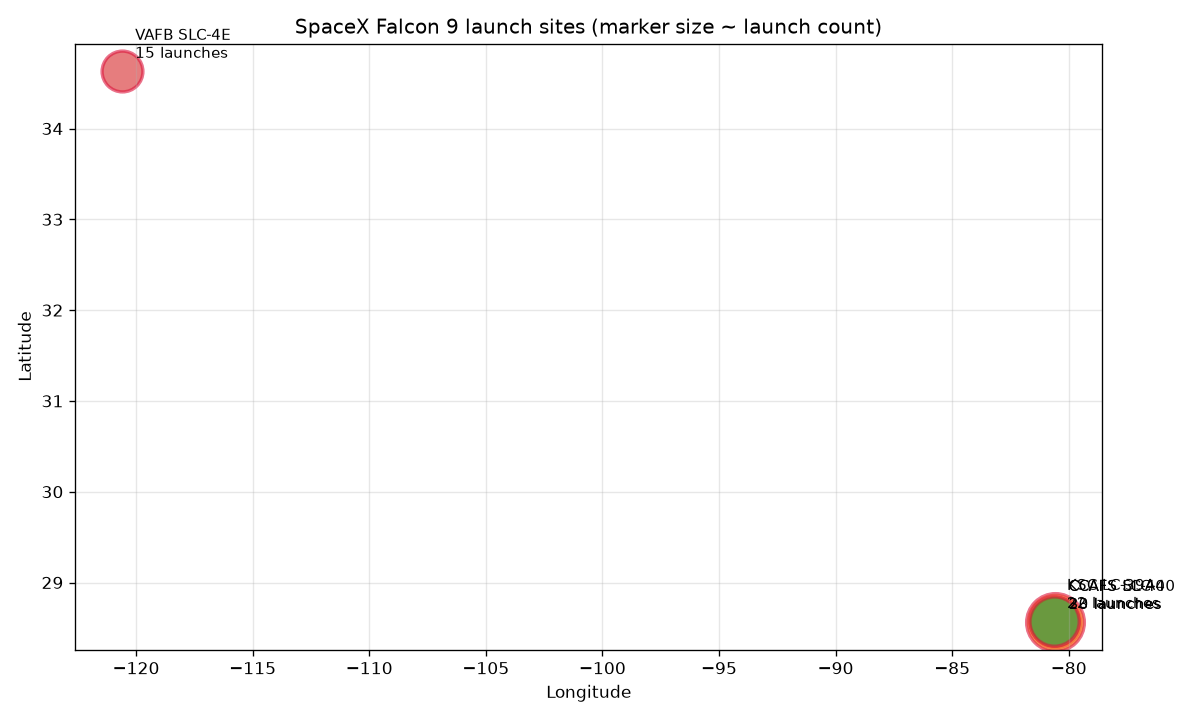

In [3]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))
for _, r in sites.iterrows():
    ax.scatter(r["lon"], r["lat"], s=r["launches"] * 40, alpha=0.6,
               edgecolors="crimson", linewidths=2)
    ax.annotate(f"{r['LaunchSite']}\n{r['launches']} launches",
                (r["lon"], r["lat"]), fontsize=9,
                xytext=(8, 8), textcoords="offset points")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("SpaceX Falcon 9 launch sites (marker size ~ launch count)")
ax.grid(True, alpha=0.3)
fig.tight_layout(); fig.savefig("../assets/launch_sites_static.png", dpi=120)
from IPython.display import Image
Image("../assets/launch_sites_static.png")

### Findings
* Three east-coast sites (Florida) handle the bulk of launches; VAFB (California)
  serves polar / SSO missions.
* Proximity to the equator (Cape Canaveral / KSC) favours GTO missions; RTLS
  landings concentrate at LZ-1/LZ-2/LZ-4 next to the Florida pads, while ASDS
  drone-ship recoveries serve higher-energy trajectories.